# Online Retail II — Data Cleaning & Exploratory Analysis

Exploration and cleaning of ~1.07M transactions from a UK-based online gift retailer (Dec 2009 – Dec 2011).

**Sections**
1. Load & combine data
2. Data quality checks (missing values, duplicates, column-by-column)
3. Seasonality & peak months
4. Outliers & special transaction types
5. Monthly trend
6. Cleaning
7. Output tables (product & customer level)

## 1. Load & combine data

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import zscore
from scipy.stats import skew

pd.set_option("display.max_rows", 60)

data2 = pd.read_csv("online_retail_10_11.csv.gz")
data1 = pd.read_csv("online_retail_09_10.csv.gz")

display(data1.head())
display(data2.head())

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/2009 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/2009 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/2009 7:45,1.25,13085.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,12/1/2010 8:26,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,12/1/2010 8:26,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,12/1/2010 8:26,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,12/1/2010 8:26,3.39,17850.0,United Kingdom


In [2]:
data = pd.concat([data1, data2], ignore_index=True)

display(data.head())
display(data.tail())

print(data.shape)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/2009 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/2009 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/2009 7:45,1.25,13085.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
1067366,581587,22899,CHILDREN'S APRON DOLLY GIRL,6,12/9/2011 12:50,2.10,12680.0,France
1067367,581587,23254,CHILDRENS CUTLERY DOLLY GIRL,4,12/9/2011 12:50,4.15,12680.0,France
1067368,581587,23255,CHILDRENS CUTLERY CIRCUS PARADE,4,12/9/2011 12:50,4.15,12680.0,France
1067369,581587,22138,BAKING SET 9 PIECE RETROSPOT,3,12/9/2011 12:50,4.95,12680.0,France
1067370,581587,POST,POSTAGE,1,12/9/2011 12:50,18.00,12680.0,France


(1067371, 8)


## 2. Data quality checks

In [3]:
display(data.columns)

Index(['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country'],
      dtype='str')

In [4]:
col = ['InvoiceNo', 'StockCode', 'Description', 'Quantity', 'InvoiceDate',
       'UnitPrice', 'CustomerID', 'Country']
print(len(col))
df = pd.DataFrame(data[col])
display(df.head())

8


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,489434,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,12/1/2009 7:45,6.95,13085.0,United Kingdom
1,489434,79323P,PINK CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
2,489434,79323W,WHITE CHERRY LIGHTS,12,12/1/2009 7:45,6.75,13085.0,United Kingdom
3,489434,22041,"RECORD FRAME 7"" SINGLE SIZE",48,12/1/2009 7:45,2.10,13085.0,United Kingdom
4,489434,21232,STRAWBERRY CERAMIC TRINKET BOX,24,12/1/2009 7:45,1.25,13085.0,United Kingdom


In [5]:
print(df.dtypes)
numeric = df.select_dtypes(include="number").columns.tolist()
print("Num:", numeric)

categorical = df.select_dtypes(include=["object", "category"]).columns.tolist()
print("Cat:", categorical)

InvoiceNo          str
StockCode          str
Description        str
Quantity         int64
InvoiceDate        str
UnitPrice      float64
CustomerID     float64
Country            str
dtype: object
Num: ['Quantity', 'UnitPrice', 'CustomerID']
Cat: ['InvoiceNo', 'StockCode', 'Description', 'InvoiceDate', 'Country']


/tmp/ipykernel_532/3934025932.py:5: Pandas4Warning: For backward compatibility, 'str' dtypes are included by select_dtypes when 'object' dtype is specified. This behavior is deprecated and will be removed in a future version. Explicitly pass 'str' to `include` to select them, or to `exclude` to remove them and silence this warning.
See https://pandas.pydata.org/docs/user_guide/migration-3-strings.html#string-migration-select-dtypes for details on how to write code that works with pandas 2 and 3.
  categorical = df.select_dtypes(include=["object", "category"]).columns.tolist()


In [6]:
df[col].info()

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   InvoiceNo    1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   UnitPrice    1067371 non-null  float64
 6   CustomerID   824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB


In [7]:
display(df[col].isna().sum())

InvoiceNo           0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     243007
Country             0
dtype: int64

In [8]:
display(df[df.duplicated()].head(20))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
371,489517,21912,VINTAGE SNAKES & LADDERS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom
383,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,12/1/2009 11:34,0.85,16329.0,United Kingdom
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,12/1/2009 11:34,0.65,16329.0,United Kingdom
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,12/1/2009 11:34,3.75,16329.0,United Kingdom
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom
390,489517,84951A,S/4 PISTACHIO LOVEBIRD COASTERS,1,12/1/2009 11:34,2.55,16329.0,United Kingdom
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,12/1/2009 11:34,1.95,16329.0,United Kingdom
394,489517,21912,VINTAGE SNAKES & LADDERS,1,12/1/2009 11:34,3.75,16329.0,United Kingdom
657,489529,22028,PENNY FARTHING BIRTHDAY CARD,12,12/1/2009 11:51,0.42,17984.0,United Kingdom
658,489529,22036,DINOSAUR BIRTHDAY CARD,12,12/1/2009 11:51,0.42,17984.0,United Kingdom


In [9]:
data.info()
print("\nMissing values:\n", data.isnull().sum())
print("\nExact duplicate rows:", data.duplicated().sum())

<class 'pandas.DataFrame'>
RangeIndex: 1067371 entries, 0 to 1067370
Data columns (total 8 columns):
 #   Column       Non-Null Count    Dtype  
---  ------       --------------    -----  
 0   InvoiceNo    1067371 non-null  str    
 1   StockCode    1067371 non-null  str    
 2   Description  1062989 non-null  str    
 3   Quantity     1067371 non-null  int64  
 4   InvoiceDate  1067371 non-null  str    
 5   UnitPrice    1067371 non-null  float64
 6   CustomerID   824364 non-null   float64
 7   Country      1067371 non-null  str    
dtypes: float64(2), int64(1), str(5)
memory usage: 65.1 MB

Missing values:
 InvoiceNo           0
StockCode           0
Description      4382
Quantity            0
InvoiceDate         0
UnitPrice           0
CustomerID     243007
Country             0
dtype: int64



Exact duplicate rows: 34335


In [10]:
# Are missing CustomerIDs concentrated in a specific country or time period?
missing_cust = data[data['CustomerID'].isnull()]

print(missing_cust['Country'].value_counts().head(10))
print("\nMissing CustomerID by month:")
print(pd.to_datetime(missing_cust['InvoiceDate']).dt.to_period('M').value_counts().sort_index())

# Compare Quantity between rows with vs. without CustomerID
print("\nQuantity - with CustomerID:", data[data['CustomerID'].notnull()]['Quantity'].describe())
print("\nQuantity - missing CustomerID:", missing_cust['Quantity'].describe())

# Are rows missing CustomerID regular orders, or cancellations?
print("\n% cancelled invoices (C) among rows missing CustomerID:", 
      missing_cust['InvoiceNo'].astype(str).str.startswith('C').mean() * 100)

Country
United Kingdom          240029
EIRE                      1671
Hong Kong                  364
Unspecified                232
France                     128
Switzerland                125
Portugal                   116
United Arab Emirates       114
Bahrain                     67
Israel                      47
Name: count, dtype: int64

Missing CustomerID by month:
InvoiceDate
2009-12    13468
2010-01     9116
2010-02     5482
2010-03     8397
2010-04     6224
2010-05     5719
2010-06     8033
2010-07     5637
2010-08     6364
2010-09     6705
2010-10     8537
2010-11    16525
2010-12    23351
2011-01    13235
2011-02     7344
2011-03     8926
2011-04     6718
2011-05     8122
2011-06     9038
2011-07    12016
2011-08     7622
2011-09     9404
2011-10    10047
2011-11    19113
2011-12     7864
Freq: M, Name: count, dtype: int64

Quantity - with CustomerID: count    824364.000000
mean         12.414574
std         188.976099
min      -80995.000000
25%           2.000000
50%       


% cancelled invoices (C) among rows missing CustomerID: 0.30863308464365224


In [11]:
missing_desc = data[data['Description'].isnull()]
print(missing_desc[['StockCode','UnitPrice','CustomerID']].head(20))
print("\nUnitPrice of rows missing Description:", missing_desc['UnitPrice'].describe())

      StockCode  UnitPrice  CustomerID
470       21646        0.0         NaN
3114      20683        0.0         NaN
3161      21350        0.0         NaN
3731      84292        0.0         NaN
4296      18010        0.0         NaN
4566     85049G        0.0         NaN
6378     35751C        0.0         NaN
6555     79323G        0.0         NaN
6576      21098        0.0         NaN
6581      21166        0.0         NaN
7204      21982        0.0         NaN
7205      21982        0.0         NaN
7559      20620        0.0         NaN
8553      85064        0.0         NaN
9249     84508B        0.0         NaN
9667      21558        0.0         NaN
10236     84347        0.0         NaN
10508     21493        0.0         NaN
11973     21489        0.0         NaN
12237     21490        0.0         NaN

UnitPrice of rows missing Description: count    4382.0
mean        0.0
std         0.0
min         0.0
25%         0.0
50%         0.0
75%         0.0
max         0.0
Name: UnitPri

In [12]:
# Note: all rows missing Description have UnitPrice = 0; several also have no CustomerID

In [13]:
missing_desc = data[data['Description'].isnull()]

print("Total rows missing Description:", missing_desc.shape[0])
print("Rows with UnitPrice != 0:", (missing_desc['UnitPrice'] != 0).sum())
print("Rows with non-null CustomerID:", missing_desc['CustomerID'].notnull().sum())
print("Rows with negative Quantity:", (missing_desc['Quantity'] < 0).sum())
print("Rows with positive Quantity:", (missing_desc['Quantity'] > 0).sum())

# Do these InvoiceNos follow a special pattern (e.g. start with a letter)?
print(missing_desc['InvoiceNo'].astype(str).str[0].value_counts())

Total rows missing Description: 4382
Rows with UnitPrice != 0: 0
Rows with non-null CustomerID: 0
Rows with negative Quantity: 2689
Rows with positive Quantity: 1693
InvoiceNo
5    3334
4    1048
Name: count, dtype: int64


In [14]:
# Column-by-column checks

In [15]:
print("Unique:", data['InvoiceNo'].nunique())

# Is InvoiceNo always numeric, or does it contain letters (e.g. 'C' = cancelled)?
import re
non_numeric = data[~data['InvoiceNo'].astype(str).str.match(r'^\d+$')]
print("Rows with non-numeric InvoiceNo:", non_numeric.shape[0])
print(non_numeric['InvoiceNo'].astype(str).str[0].value_counts())  # first character breakdown
non_numeric.head(10)

Unique: 53628


Rows with non-numeric InvoiceNo: 19500
InvoiceNo
C    19494
A        6
Name: count, dtype: int64


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,12/1/2009 10:33,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,12/1/2009 10:33,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,12/1/2009 10:33,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,12/1/2009 10:33,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,12/1/2009 10:33,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,12/1/2009 10:33,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,12/1/2009 10:33,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,12/1/2009 10:33,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,12/1/2009 10:33,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,12/1/2009 10:44,4.25,17592.0,United Kingdom


In [16]:
print("Unique:", data['StockCode'].nunique())
print(data['StockCode'].astype(str).str.len().value_counts())  # are code lengths consistent?

# Any non-standard codes (e.g. "POST", "D", "M", "BANK CHARGES")?
weird_codes = data[data['StockCode'].astype(str).str.match(r'^[A-Za-z]+$')]
print("StockCodes made of letters only:\n", weird_codes['StockCode'].value_counts())

Unique: 5305
StockCode
5     932385
6     127590
4       2158
1       1713
3       1446
7       1393
2        283
12       202
8        127
9         74
Name: count, dtype: int64


StockCodes made of letters only:
 StockCode
POST         2122
DOT          1446
M            1421
D             177
S             104
ADJUST         67
AMAZONFEE      43
DCGSSGIRL      25
DCGSSBOY       23
PADS           19
CRUK           16
B               6
m               5
GIFT            1
DCGSLBOY        1
DCGSLGIRL       1
Name: count, dtype: int64


In [17]:
# Extra whitespace / inconsistent capitalization in Description?
print(data['Description'].str.strip().ne(data['Description']).sum(), "rows with leading/trailing whitespace")

# Any suspicious descriptions (e.g. "?", "damaged", "check")?
suspicious = data[data['Description'].astype(str).str.contains(
    r'\?|damaged|missing|lost|check|test|sample|wrong', case=False, na=False)]
print("Rows with suspicious Description:", suspicious.shape[0])
suspicious['Description'].value_counts().head(20)

217417 rows with leading/trailing whitespace


Rows with suspicious Description: 1334


Description
BROWN CHECK CAT DOORSTOP              472
check                                 162
SUNSET CHECK HAMMOCK                  115
SAMPLES                               104
PAIR PADDED HANGERS PINK CHECK        100
?                                      92
damaged                                81
missing                                27
MULTICOLOUR CRUSOE CHECK LAMPSHADE     17
Damaged                                17
This is a test product.                16
BLUE CHECK BAG W HANDLE 34X20CM        11
checked                                 8
damages?                                7
BLUE CRUSOE CHECK LAMPSHADE             7
??                                      7
wet damaged                             5
test                                    3
CHECK                                   3
lost                                    2
Name: count, dtype: int64

In [18]:
print("\nRows with negative Quantity:", (data['Quantity'] < 0).sum())
print("Rows with Quantity = 0:", (data['Quantity'] == 0).sum())
print("Rows with very large Quantity (>5000):", (data['Quantity'] > 5000).sum())

# Do negative quantities correspond to cancelled invoices (InvoiceNo starting with 'C')?
neg_qty = data[data['Quantity'] < 0]
print(neg_qty['InvoiceNo'].astype(str).str.startswith('C').mean() * 100, "% of negative-Quantity rows are cancellations")


Rows with negative Quantity: 22950
Rows with Quantity = 0: 0
Rows with very large Quantity (>5000): 35
84.93681917211329 % of negative-Quantity rows are cancellations


In [19]:
print("Rows with negative UnitPrice:", (data['UnitPrice'] < 0).sum())
print("Rows with UnitPrice = 0:", (data['UnitPrice'] == 0).sum())

# What items have zero or negative price?
data[data['UnitPrice'] <= 0][['StockCode','Description','UnitPrice']].value_counts().head(20)

Rows with negative UnitPrice: 5
Rows with UnitPrice = 0: 6202


StockCode  Description                          UnitPrice
21116      OWL DOORSTOP                         0.0          15
46000M     POLYESTER FILLER PAD 45x45cm         0.0          12
46000S     POLYESTER FILLER PAD 40x40cm         0.0          10
22624      IVORY KITCHEN SCALES                 0.0          10
22676      FRENCH BLUE METAL DOOR SIGN 1        0.0          10
22501      PICNIC BASKET WICKER LARGE           0.0           9
22372      AIRLINE BAG VINTAGE WORLD CHAMPION   0.0           9
84692      BOX OF 24 COCKTAIL PARASOLS          0.0           9
22625      RED KITCHEN SCALES                   0.0           9
22683      FRENCH BLUE METAL DOOR SIGN 8        0.0           9
22514      CHILDS GARDEN SPADE BLUE             0.0           8
22627      MINT KITCHEN SCALES                  0.0           8
22666      RECIPE BOX PANTRY YELLOW DESIGN      0.0           8
22679      FRENCH BLUE METAL DOOR SIGN 4        0.0           8
22686      FRENCH BLUE METAL DOOR SIGN No     

In [20]:
# TODO: also check zero-price rows by CustomerID

In [21]:
# Check date format before converting
print(data['InvoiceDate'].dtype)
print(data['InvoiceDate'].head())

test_dates = pd.to_datetime(data['InvoiceDate'], errors='coerce')
print(test_dates.isnull().sum())

print("Min date:", test_dates.min())
print("Max date:", test_dates.max())

str
0    12/1/2009 7:45
1    12/1/2009 7:45
2    12/1/2009 7:45
3    12/1/2009 7:45
4    12/1/2009 7:45
Name: InvoiceDate, dtype: str


0


Min date: 2009-12-01 07:45:00
Max date: 2011-12-09 12:50:00


In [22]:
print(data['Country'].unique())
print(data['Country'].value_counts())


<StringArray>
[      'United Kingdom',               'France',                  'USA',
              'Belgium',            'Australia',                 'EIRE',
              'Germany',             'Portugal',                'Japan',
              'Denmark',              'Nigeria',          'Netherlands',
               'Poland',                'Spain',      'Channel Islands',
                'Italy',               'Cyprus',               'Greece',
               'Norway',              'Austria',               'Sweden',
 'United Arab Emirates',              'Finland',          'Switzerland',
          'Unspecified',                'Malta',              'Bahrain',
                  'RSA',              'Bermuda',            'Hong Kong',
            'Singapore',             'Thailand',               'Israel',
            'Lithuania',          'West Indies',              'Lebanon',
                'Korea',               'Brazil',               'Canada',
              'Iceland',         'Sau

### Rows with Country = 'Unspecified'

In [23]:
unspec = data[data['Country'] == 'Unspecified']
print(unspec.shape)
display(unspec.head(20))

(756, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61394,494860,84832,ZINC WILLIE WINKIE CANDLE STICK,5,1/19/2010 11:01,0.85,12470.0,Unspecified
61395,494860,84836,ZINC METAL HEART DECORATION,5,1/19/2010 11:01,1.25,12470.0,Unspecified
61396,494860,85014D,PINK/BROWN DOTS RUFFLED UMBRELLA,1,1/19/2010 11:01,5.95,12470.0,Unspecified
61397,494860,85014A,BLACK/BLUE DOTS RUFFLED UMBRELLA,1,1/19/2010 11:01,5.95,12470.0,Unspecified
61398,494860,85014B,RED/WHITE DOTS RUFFLED UMBRELLA,2,1/19/2010 11:01,5.95,12470.0,Unspecified
61399,494860,21034,REX CASH+CARRY JUMBO SHOPPER,1,1/19/2010 11:01,0.95,12470.0,Unspecified
61400,494860,20685,RED SPOTTY COIR DOORMAT,1,1/19/2010 11:01,6.75,12470.0,Unspecified
61401,494860,84824,DANISH ROSE UMBRELLA STAND,1,1/19/2010 11:01,15.95,12470.0,Unspecified
61402,494860,85123A,WHITE HANGING HEART T-LIGHT HOLDER,7,1/19/2010 11:01,2.95,12470.0,Unspecified
61403,494860,84970L,SINGLE HEART ZINC T-LIGHT HOLDER,5,1/19/2010 11:01,0.95,12470.0,Unspecified


In [24]:
unspec = data[data['Country'] == 'Unspecified']

# Unspecified-country rows with missing CustomerID
unspec_no_cust = unspec[unspec['CustomerID'].isnull()]
print("Rows:", unspec_no_cust.shape[0])
display(unspec_no_cust)

# Unspecified-country rows WITH CustomerID (for comparison)
unspec_has_cust = unspec[unspec['CustomerID'].notnull()]
print("Rows:", unspec_has_cust.shape[0])
display(unspec_has_cust.head(20))

Rows: 232


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
437145,531208,75131,METAL TUBE CHIME ON BAMBOO,1,11/5/2010 16:03,1.69,NaN,Unspecified
437146,531208,22306,SILVER MUG BONE CHINA TREE OF LIFE,4,11/5/2010 16:03,1.95,NaN,Unspecified
437147,531208,21038,SET/4 MODERN VINTAGE COTTON NAPKINS,1,11/5/2010 16:03,2.95,NaN,Unspecified
437148,531208,21836,GINGHAM OVEN GLOVE RED HEART,2,11/5/2010 16:03,3.75,NaN,Unspecified
437149,531208,22249,DECORATION WHITE CHICK MAGIC GARDEN,6,11/5/2010 16:03,0.85,NaN,Unspecified
...,...,...,...,...,...,...,...,...
1024239,578539,22560,TRADITIONAL MODELLING CLAY,24,11/24/2011 14:55,1.25,NaN,Unspecified
1024240,578539,23570,TRADITIONAL PICK UP STICKS GAME,12,11/24/2011 14:55,1.25,NaN,Unspecified
1024241,578539,23571,TRADITIONAL NAUGHTS & CROSSES,12,11/24/2011 14:55,1.65,NaN,Unspecified
1024242,578539,84992,72 SWEETHEART FAIRY CAKE CASES,24,11/24/2011 14:55,0.55,NaN,Unspecified


Rows: 524


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
61394,494860,84832,ZINC WILLIE WINKIE CANDLE STICK,5,1/19/2010 11:01,0.85,12470.0,Unspecified
61395,494860,84836,ZINC METAL HEART DECORATION,5,1/19/2010 11:01,1.25,12470.0,Unspecified
61396,494860,85014D,PINK/BROWN DOTS RUFFLED UMBRELLA,1,1/19/2010 11:01,5.95,12470.0,Unspecified
61397,494860,85014A,BLACK/BLUE DOTS RUFFLED UMBRELLA,1,1/19/2010 11:01,5.95,12470.0,Unspecified
61398,494860,85014B,RED/WHITE DOTS RUFFLED UMBRELLA,2,1/19/2010 11:01,5.95,12470.0,Unspecified
61399,494860,21034,REX CASH+CARRY JUMBO SHOPPER,1,1/19/2010 11:01,0.95,12470.0,Unspecified
61400,494860,20685,RED SPOTTY COIR DOORMAT,1,1/19/2010 11:01,6.75,12470.0,Unspecified
61401,494860,84824,DANISH ROSE UMBRELLA STAND,1,1/19/2010 11:01,15.95,12470.0,Unspecified
61402,494860,85123A,WHITE HANGING HEART T-LIGHT HOLDER,7,1/19/2010 11:01,2.95,12470.0,Unspecified
61403,494860,84970L,SINGLE HEART ZINC T-LIGHT HOLDER,5,1/19/2010 11:01,0.95,12470.0,Unspecified


In [25]:
# Are Unspecified-country rows valid when CustomerID is missing?

In [26]:
display(unspec[unspec['Quantity'] < 0]) # should be removed: negative quantity

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
71053,C495770,ADJUST,Adjustment by john on 26/01/2010 16,-1,1/26/2010 16:49,36.75,15357.0,Unspecified
270810,C515620,M,Manual,-1,7/14/2010 9:35,1189.94,16320.0,Unspecified
324554,C521020,84534B,FAIRY CAKE NOTEBOOK A5 SIZE,-12,9/1/2010 15:08,0.85,16320.0,Unspecified
452157,C532353,21333,CLASSIC WHITE FRAME,-4,11/11/2010 16:32,2.95,NaN,Unspecified


In [27]:
display(unspec[unspec['UnitPrice'] > 100].sort_values('UnitPrice', ascending=False)) # unusual descriptions with high unit prices

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
270810,C515620,M,Manual,-1,7/14/2010 9:35,1189.94,16320.0,Unspecified


## 3. Seasonality & peak months

In [28]:
data['InvoiceDate'] = pd.to_datetime(data['InvoiceDate'])
data['YearMonth'] = data['InvoiceDate'].dt.to_period('M')

monthly_invoices = data.groupby('YearMonth')['InvoiceNo'].nunique().sort_values(ascending=False)
print(monthly_invoices.head(10))  # months with the most invoices = true peak

YearMonth
2010-11    3669
2011-11    3462
2010-10    2965
2011-10    2637
2010-05    2418
2010-09    2375
2010-03    2367
2009-12    2330
2011-09    2327
2010-06    2216
Freq: M, Name: InvoiceNo, dtype: int64


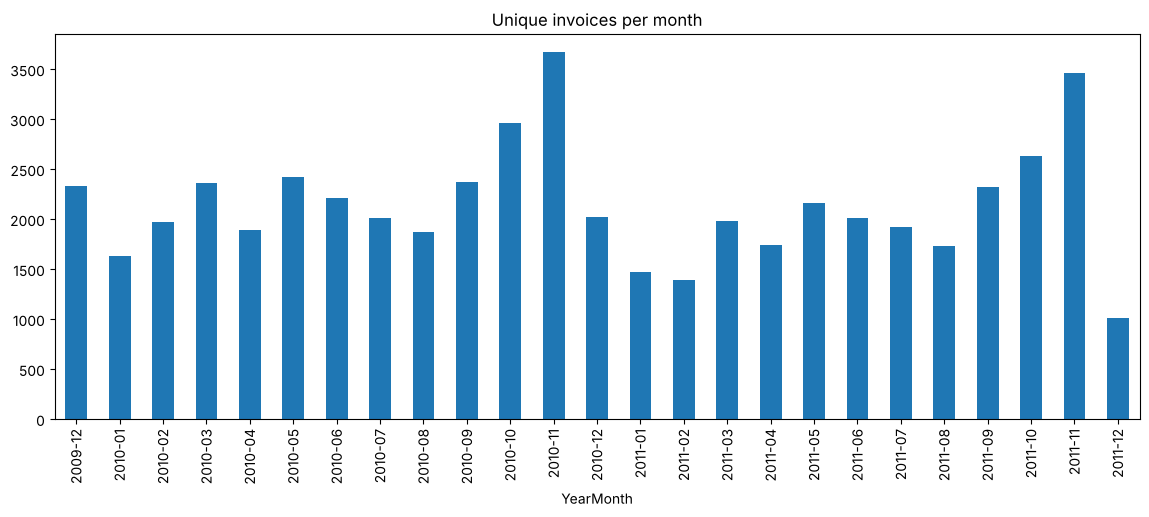

In [29]:
monthly = data.groupby('YearMonth')['InvoiceNo'].nunique()
monthly.plot(kind='bar', figsize=(14,5), title='Unique invoices per month')
plt.show()

In [30]:
# Top 3 months by number of invoices
peak_months = monthly_invoices.head(3).index
peak = data[data['YearMonth'].isin(peak_months)]

# Top products by revenue in peak months
peak = peak.copy()
peak['TotalPrice'] = peak['Quantity'] * peak['UnitPrice']
peak_revenue = peak.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(20)
print(peak_revenue)

# Show raw rows for the #1 product to sanity-check
top1 = peak_revenue.index[0]
display(peak[peak['Description'] == top1][['InvoiceNo','StockCode','Description','Quantity','InvoiceDate','UnitPrice','YearMonth']].head(20))

Description
PAPER CHAIN KIT 50'S CHRISTMAS         65634.42
REGENCY CAKESTAND 3 TIER               61720.47
DOTCOM POSTAGE                         59266.75
WHITE HANGING HEART T-LIGHT HOLDER     44364.98
ROTATING SILVER ANGELS T-LIGHT HLDR    44252.56
RABBIT NIGHT LIGHT                     34422.09
PAPER CHAIN KIT VINTAGE CHRISTMAS      34072.08
ASSORTED COLOUR BIRD ORNAMENT          31956.17
JUMBO BAG RED RETROSPOT                31033.92
CHILLI LIGHTS                          24301.34
POSTAGE                                23891.48
HOT WATER BOTTLE TEA AND SYMPATHY      22148.17
CHOCOLATE HOT WATER BOTTLE             20211.12
3 HEARTS HANGING DECORATION RUSTIC     18147.13
HAND WARMER OWL DESIGN                 18078.89
BLACK RECORD COVER FRAME               17754.23
HAND WARMER SCOTTY DOG DESIGN          17744.82
SCOTTIE DOG HOT WATER BOTTLE           16356.83
SET OF 6 RIBBONS VINTAGE CHRISTMAS     16094.41
RED WOOLLY HOTTIE WHITE HEART.         15034.14
Name: TotalPrice, dtype: flo

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,YearMonth
365934,524868,22086,PAPER CHAIN KIT 50'S CHRISTMAS,6,2010-10-01 09:36:00,2.95,2010-10
366261,524936,22086,PAPER CHAIN KIT 50'S CHRISTMAS,6,2010-10-01 11:58:00,2.95,2010-10
367591,525000,22086,PAPER CHAIN KIT 50'S CHRISTMAS,40,2010-10-03 10:13:00,2.55,2010-10
368198,525020,22086,PAPER CHAIN KIT 50'S CHRISTMAS,4,2010-10-03 11:53:00,2.95,2010-10
368559,525036,22086,PAPER CHAIN KIT 50'S CHRISTMAS,6,2010-10-03 12:34:00,2.95,2010-10
369166,525065,22086,PAPER CHAIN KIT 50'S CHRISTMAS,3,2010-10-03 14:28:00,2.95,2010-10
369327,525070,22086,PAPER CHAIN KIT 50'S CHRISTMAS,2,2010-10-03 14:47:00,2.95,2010-10
370017,525097,22086,PAPER CHAIN KIT 50'S CHRISTMAS,80,2010-10-04 09:37:00,2.55,2010-10
370052,525100,22086,PAPER CHAIN KIT 50'S CHRISTMAS,6,2010-10-04 10:00:00,2.95,2010-10
370357,525129,22086,PAPER CHAIN KIT 50'S CHRISTMAS,5,2010-10-04 11:44:00,2.95,2010-10


In [31]:
for ym in peak_months:
    print(f"\n=== {ym} ===")
    sub = data[data['YearMonth'] == ym]
    sub = sub.copy()
    sub['TotalPrice'] = sub['Quantity'] * sub['UnitPrice']
    print(sub.groupby('Description')['TotalPrice'].sum().sort_values(ascending=False).head(10))


=== 2010-11 ===
Description
PAPER CHAIN KIT 50'S CHRISTMAS         28321.16
REGENCY CAKESTAND 3 TIER               26146.13
ROTATING SILVER ANGELS T-LIGHT HLDR    25710.94
WHITE HANGING HEART T-LIGHT HOLDER     18046.00
DOTCOM POSTAGE                         15289.92
PAPER CHAIN KIT VINTAGE CHRISTMAS      14270.32
ASSORTED COLOUR BIRD ORNAMENT          14083.93
JUMBO BAG RED RETROSPOT                11415.22
SMALL POPCORN HOLDER                   10259.99
HAND WARMER OWL DESIGN                  9618.58
Name: TotalPrice, dtype: float64

=== 2011-11 ===
Description
DOTCOM POSTAGE                        36905.40
RABBIT NIGHT LIGHT                    34422.09
PAPER CHAIN KIT 50'S CHRISTMAS        28883.04
WHITE HANGING HEART T-LIGHT HOLDER    14345.22
POPCORN HOLDER                        13968.74
PAPER CHAIN KIT VINTAGE CHRISTMAS     12831.54
REGENCY CAKESTAND 3 TIER              12798.48
HOT WATER BOTTLE KEEP CALM            11500.87
CHILLI LIGHTS                         11475.07
JUMBO 

In [32]:
# Most top sellers in peak months are Christmas decorations

In [33]:
peak = data[data['InvoiceDate'].dt.month.isin([10,11,12])]
print(peak['Description'].value_counts().head(20))

# Compare with the rest of the year
off_peak = data[~data['InvoiceDate'].dt.month.isin([10,11,12])]
print(off_peak['Description'].value_counts().head(20))

Description
WHITE HANGING HEART T-LIGHT HOLDER     1941
PAPER CHAIN KIT 50'S CHRISTMAS         1775
REGENCY CAKESTAND 3 TIER               1371
PAPER CHAIN KIT VINTAGE CHRISTMAS      1267
SCOTTIE DOG HOT WATER BOTTLE           1259
CHOCOLATE HOT WATER BOTTLE             1221
HOT WATER BOTTLE TEA AND SYMPATHY      1196
JUMBO BAG RED RETROSPOT                1189
HAND WARMER OWL DESIGN                 1165
ASSORTED COLOUR BIRD ORNAMENT          1096
HAND WARMER SCOTTY DOG DESIGN          1058
REX CASH+CARRY JUMBO SHOPPER           1034
HAND WARMER BIRD DESIGN                1031
SET OF 20 VINTAGE CHRISTMAS NAPKINS     967
HAND WARMER UNION JACK                  951
60 CAKE CASES VINTAGE CHRISTMAS         921
WHITE SKULL HOT WATER BOTTLE            905
VINTAGE SNAP CARDS                      867
HEART OF WICKER LARGE                   863
RED HANGING HEART T-LIGHT HOLDER        856
Name: count, dtype: int64


Description
WHITE HANGING HEART T-LIGHT HOLDER    3977
REGENCY CAKESTAND 3 TIER              3041
JUMBO BAG RED RETROSPOT               2280
PARTY BUNTING                         2247
STRAWBERRY CERAMIC TRINKET BOX        1882
ASSORTED COLOUR BIRD ORNAMENT         1862
LUNCH BAG  BLACK SKULL.               1756
JUMBO STORAGE BAG SUKI                1712
JUMBO SHOPPER VINTAGE RED PAISLEY     1656
60 TEATIME FAIRY CAKE CASES           1611
LUNCH BAG SPACEBOY DESIGN             1598
LUNCH BAG CARS BLUE                   1596
HOME BUILDING BLOCK WORD              1534
HEART OF WICKER SMALL                 1501
JUMBO BAG STRAWBERRY                  1477
LUNCH BAG WOODLAND                    1476
PACK OF 60 PINK PAISLEY CAKE CASES    1469
BAKING SET 9 PIECE RETROSPOT          1404
WOODEN FRAME ANTIQUE WHITE            1403
NATURAL SLATE HEART CHALKBOARD        1391
Name: count, dtype: int64


## 4. Outliers & special transaction types

In [34]:
data['InvoiceNo_HasLetter'] = data['InvoiceNo'].astype(str).str.contains(r'[A-Za-z]')
print(data['InvoiceNo_HasLetter'].value_counts())
data[data['InvoiceNo_HasLetter']]['InvoiceNo'].astype(str).str[0].value_counts()

InvoiceNo_HasLetter
False    1047871
True       19500
Name: count, dtype: int64


InvoiceNo
C    19494
A        6
Name: count, dtype: int64

In [35]:
a_invoices = data[data['InvoiceNo'].astype(str).str.startswith('A')]
display(a_invoices)

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,2010-04,True
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,2010-07,True
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,2010-10,True
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,2011-08,True
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,2011-08,True
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,2011-08,True


In [36]:
inv_str = data['InvoiceNo'].astype(str)
non_numeric_inv = data[~inv_str.str.match(r'^\d+$')]

pd.set_option('display.max_rows', 50)
display(non_numeric_inv[['InvoiceNo','StockCode','Description','Quantity','UnitPrice','CustomerID','Country']].head(50))
# most non-numeric invoices have Quantity < 0

,InvoiceNo,StockCode,Description,Quantity,UnitPrice,CustomerID,Country
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2.95,16321.0,Australia
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,1.65,16321.0,Australia
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,4.25,16321.0,Australia
181,C489449,21896,POTTING SHED TWINE,-6,2.10,16321.0,Australia
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2.95,16321.0,Australia
183,C489449,21871,SAVE THE PLANET MUG,-12,1.25,16321.0,Australia
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,1.25,16321.0,Australia
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,0.85,16321.0,Australia
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2.95,16321.0,Australia
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,4.25,17592.0,United Kingdom


In [37]:
print(data['UnitPrice'].describe())
print(data['UnitPrice'].sort_values(ascending=False).head(20))

# Zscore
data['zscore_price'] = zscore(data['UnitPrice'])
print("Price outliers (|z|>3):", (data['zscore_price'].abs() > 3).sum())

# Which items are they?
data.sort_values('UnitPrice', ascending=False)[['StockCode','Description','UnitPrice','Quantity']].head(20)

count    1.067371e+06
mean     4.649388e+00
std      1.235531e+02
min     -5.359436e+04
25%      1.250000e+00
50%      2.100000e+00
75%      4.150000e+00
max      3.897000e+04
Name: UnitPrice, dtype: float64
748142     38970.00
241824     25111.09
241827     25111.09
320581     18910.69
1050063    17836.46
569163     16888.02
569164     16453.71
519294     13541.33
540478     13541.33
540477     13541.33
517953     13541.33
517955     13541.33
541817     13541.33
541463     13474.79
519170     13474.79
1050062    11586.50
825443     11062.06
135012     10953.50
135013     10953.50
135015     10953.50
Name: UnitPrice, dtype: float64
Price outliers (|z|>3): 634


,StockCode,Description,UnitPrice,Quantity
748142,M,Manual,38970.00,-1
241824,M,Manual,25111.09,-1
241827,M,Manual,25111.09,1
320581,BANK CHARGES,Bank Charges,18910.69,-1
1050063,AMAZONFEE,AMAZON FEE,17836.46,-1
569163,AMAZONFEE,AMAZON FEE,16888.02,-1
569164,AMAZONFEE,AMAZON FEE,16453.71,-1
519294,AMAZONFEE,AMAZON FEE,13541.33,-1
540478,AMAZONFEE,AMAZON FEE,13541.33,1
540477,AMAZONFEE,AMAZON FEE,13541.33,-1


In [38]:
display(data[data['Quantity'] < 0].head(20))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price
178,C489449,22087,PAPER BUNTING WHITE LACE,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,2009-12,True,-0.013754
179,C489449,85206A,CREAM FELT EASTER EGG BASKET,-6,2009-12-01 10:33:00,1.65,16321.0,Australia,2009-12,True,-0.024276
180,C489449,21895,POTTING SHED SOW 'N' GROW SET,-4,2009-12-01 10:33:00,4.25,16321.0,Australia,2009-12,True,-0.003233
181,C489449,21896,POTTING SHED TWINE,-6,2009-12-01 10:33:00,2.10,16321.0,Australia,2009-12,True,-0.020634
182,C489449,22083,PAPER CHAIN KIT RETRO SPOT,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,2009-12,True,-0.013754
183,C489449,21871,SAVE THE PLANET MUG,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,2009-12,True,-0.027514
184,C489449,84946,ANTIQUE SILVER TEA GLASS ETCHED,-12,2009-12-01 10:33:00,1.25,16321.0,Australia,2009-12,True,-0.027514
185,C489449,84970S,HANGING HEART ZINC T-LIGHT HOLDER,-24,2009-12-01 10:33:00,0.85,16321.0,Australia,2009-12,True,-0.030751
186,C489449,22090,PAPER BUNTING RETRO SPOTS,-12,2009-12-01 10:33:00,2.95,16321.0,Australia,2009-12,True,-0.013754
196,C489459,90200A,PURPLE SWEETHEART BRACELET,-3,2009-12-01 10:44:00,4.25,17592.0,United Kingdom,2009-12,True,-0.003233


In [39]:
# Rows with the largest quantities
display(data.sort_values('Quantity', ascending=False).head(20))

# Use a fixed threshold, e.g. > 1000
big_qty = data[data['Quantity'] > 1000]
print("Rows with Quantity > 1000:", big_qty.shape[0])
display(big_qty.head(20))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price
1065882,581483,23843,"PAPER CRAFT , LITTLE BIRDIE",80995,2011-12-09 09:15:00,2.08,16446.0,United Kingdom,2011-12,False,-0.020796
587080,541431,23166,MEDIUM CERAMIC TOP STORAGE JAR,74215,2011-01-18 10:01:00,1.04,12346.0,United Kingdom,2011-01,False,-0.029213
90857,497946,37410,BLACK AND WHITE PAISLEY FLOWER MUG,19152,2010-02-15 11:57:00,0.10,13902.0,Denmark,2010-02,False,-0.036821
127168,501534,21091,SET/6 WOODLAND PAPER PLATES,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark,2010-03,False,-0.036821
127166,501534,21099,SET/6 STRAWBERRY PAPER CUPS,12960,2010-03-17 13:09:00,0.10,13902.0,Denmark,2010-03,False,-0.036821
127169,501534,21085,SET/6 WOODLAND PAPER CUPS,12744,2010-03-17 13:09:00,0.10,13902.0,Denmark,2010-03,False,-0.036821
1027583,578841,84826,ASSTD DESIGN 3D PAPER STICKERS,12540,2011-11-25 15:57:00,0.00,13256.0,United Kingdom,2011-11,False,-0.037631
127167,501534,21092,SET/6 STRAWBERRY PAPER PLATES,12480,2010-03-17 13:09:00,0.10,13902.0,Denmark,2010-03,False,-0.036821
192197,507637,84016,FLAG OF ST GEORGE CAR FLAG,10200,2010-05-10 14:55:00,0.00,NaN,United Kingdom,2010-05,False,-0.037631
135027,502269,21984,PACK OF 12 PINK PAISLEY TISSUES,10000,2010-03-23 15:36:00,0.25,17940.0,United Kingdom,2010-03,False,-0.035607


Rows with Quantity > 1000: 352


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price
7302,490018,21981,PACK OF 12 WOODLAND TISSUES,4320,2009-12-03 12:31:00,0.25,17940.0,United Kingdom,2009-12,False,-0.035607
7303,490018,21967,PACK OF 12 SKULL TISSUES,5184,2009-12-03 12:31:00,0.25,17940.0,United Kingdom,2009-12,False,-0.035607
7304,490018,21984,PACK OF 12 PINK PAISLEY TISSUES,4008,2009-12-03 12:31:00,0.25,17940.0,United Kingdom,2009-12,False,-0.035607
7305,490018,21980,PACK OF 12 RED SPOTTY TISSUES,4008,2009-12-03 12:31:00,0.25,17940.0,United Kingdom,2009-12,False,-0.035607
17384,490758,72008,NaN,3000,2009-12-08 09:38:00,0.00,NaN,United Kingdom,2009-12,False,-0.037631
22100,491133,16014,SMALL CHINESE STYLE SCISSOR,1500,2009-12-09 16:17:00,0.32,13848.0,United Kingdom,2009-12,False,-0.035041
23689,491212,20668,DISCO BALL CHRISTMAS DECORATION,1002,2009-12-10 14:28:00,0.10,14062.0,United Kingdom,2009-12,False,-0.036821
24815,491440,72756,FAIRY CAKE CANDLES,1080,2009-12-11 10:31:00,1.25,16029.0,United Kingdom,2009-12,False,-0.027514
33391,492185,16014,SMALL CHINESE STYLE SCISSOR,3000,2009-12-15 15:48:00,0.32,16308.0,United Kingdom,2009-12,False,-0.035041
43522,493108,47503F,NaN,2300,2009-12-22 11:23:00,0.00,NaN,United Kingdom,2009-12,False,-0.037631


In [40]:
# Description = NaN
display(data[data['Description'].isna()].head(20))

# Description = "?"
display(data[data['Description'].astype(str).str.strip() == '?'].head(20))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631
4566,489821,85049G,NaN,-240,2009-12-02 13:25:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631
6378,489882,35751C,NaN,12,2009-12-02 16:22:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631
6555,489898,79323G,NaN,954,2009-12-03 09:40:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631
6576,489901,21098,NaN,-200,2009-12-03 09:47:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631
6581,489903,21166,NaN,48,2009-12-03 09:57:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price
63439,495027,21314,?,1146,2010-01-20 13:48:00,0.0,NaN,United Kingdom,2010-01,False,-0.037631
100428,498887,20679,?,-330,2010-02-23 13:04:00,0.0,NaN,United Kingdom,2010-02,False,-0.037631
167838,505285,85221,?,-1120,2010-04-21 11:48:00,0.0,NaN,United Kingdom,2010-04,False,-0.037631
171218,505638,21929,?,-420,2010-04-23 13:41:00,0.0,NaN,United Kingdom,2010-04,False,-0.037631
183682,506866,84270,?,-3000,2010-05-04 15:20:00,0.0,NaN,United Kingdom,2010-05,False,-0.037631
193991,507856,72225D,?,-966,2010-05-11 14:53:00,0.0,NaN,United Kingdom,2010-05,False,-0.037631
194006,507871,21671,?,-144,2010-05-11 14:59:00,0.0,NaN,United Kingdom,2010-05,False,-0.037631
194012,507876,47420,?,-1000,2010-05-11 15:01:00,0.0,NaN,United Kingdom,2010-05,False,-0.037631
238366,512438,47566,?,-700,2010-06-15 16:23:00,0.0,NaN,United Kingdom,2010-06,False,-0.037631
238394,512440,47566,?,-150,2010-06-15 16:32:00,0.0,NaN,United Kingdom,2010-06,False,-0.037631


In [41]:
# UnitPrice > 100
display(data[data['UnitPrice'] > 100].sort_values('UnitPrice', ascending=False).head(20))

# UnitPrice < 0
display(data[data['UnitPrice'] < 0])

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom,2011-06,True,315.373567
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,25111.09,17399.0,United Kingdom,2010-06,True,203.203811
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom,2010-06,False,203.203811
320581,C520667,BANK CHARGES,Bank Charges,-1,2010-08-27 13:42:00,18910.69,NaN,United Kingdom,2010-08,True,153.019680
1050063,C580605,AMAZONFEE,AMAZON FEE,-1,2011-12-05 11:36:00,17836.46,NaN,United Kingdom,2011-12,True,144.325192
569163,C540117,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:55:00,16888.02,NaN,United Kingdom,2011-01,True,136.648811
569164,C540118,AMAZONFEE,AMAZON FEE,-1,2011-01-05 09:57:00,16453.71,NaN,United Kingdom,2011-01,True,133.133639
540477,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,NaN,United Kingdom,2010-12,True,109.561731
541817,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,13541.33,NaN,United Kingdom,2010-12,True,109.561731
517955,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,2010-12,False,109.561731


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,2010-04,True,-433.813902
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,2010-07,True,-356.417401
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,2010-10,True,-315.091654
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,2011-08,True,-89.570543
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,2011-08,True,-89.570543


In [42]:
print(data['Description'].nunique(), 'unique descriptions')
print(data['Description'].value_counts().tail(40))

5698 unique descriptions
Description
Had been put aside.                    1
Sale error                             1
ROCOCO WALL MIROR                      1
Amazon Adjustment                      1
wrongly marked 23343                   1
20713 wrongly marked                   1
re-adjustment                          1
Breakages                              1
20713                                  1
Marked as 23343                        1
wrongly coded 23343                    1
Found by jackie                        1
SET 10 CARDS TRIANGLE ICONS  17220     1
SET 10 CARDS CHRISTMAS BAUBLE 16954    1
wrongly marked                         1
water damaged                          1
Wrongly mrked had 85123a in box        1
wrongly marked carton 22804            1
SET 10 CARDS 3 WISE MEN 17107          1
FLOWER SHOP DESIGN MUG                 1
SET OF 6 EASTER RAINBOW CHICKS         1
amazon adjust                          1
???lost                                1
dotcomstock         

In [43]:
# Descriptions that appear fewer than 5 times are inconsistent / not in all caps

In [44]:

# Keep NaN CustomerID as its own group (dropna=False)
inv_per_customer = data.groupby('CustomerID', dropna=False)['InvoiceNo'].nunique()

print(inv_per_customer.describe())

# Top customers by number of invoices
display(inv_per_customer.sort_values(ascending=False).head(20))

count    5943.000000
mean        9.023725
std       114.549243
min         1.000000
25%         2.000000
50%         4.000000
75%         8.000000
max      8752.000000
Name: InvoiceNo, dtype: float64


CustomerID
NaN        8752
14911.0     510
12748.0     365
17841.0     289
15311.0     270
14606.0     259
13089.0     247
14156.0     202
14527.0     190
13694.0     164
14646.0     164
17850.0     159
18102.0     153
16422.0     146
15061.0     138
17949.0     138
13408.0     135
12471.0     129
16029.0     125
13798.0     125
Name: InvoiceNo, dtype: int64

In [45]:
inv_date_nunique = data.groupby('InvoiceNo')['InvoiceDate'].nunique()
bad_invoices_date = inv_date_nunique[inv_date_nunique > 1].index

rows_diff_date = data[data['InvoiceNo'].isin(bad_invoices_date)]
print("InvoiceNos with more than one InvoiceDate:", len(bad_invoices_date))
print("Rows affected:", rows_diff_date.shape[0])
display(rows_diff_date.sort_values(['InvoiceNo', 'InvoiceDate']).head(30))

InvoiceNos with more than one InvoiceDate: 83
Rows affected: 5796


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price
41630,492807,85131A,BEADED PEARL HEART WHITE ON STICK,1,2009-12-20 12:28:00,1.25,17211.0,United Kingdom,2009-12,False,-0.027514
41631,492807,85129A,"WHITE PEARL BEADED HEART, SMALL",2,2009-12-20 12:28:00,1.25,17211.0,United Kingdom,2009-12,False,-0.027514
41632,492807,85129D,BEADED CRYSTAL HEART PINK SMALL,4,2009-12-20 12:28:00,1.25,17211.0,United Kingdom,2009-12,False,-0.027514
41633,492807,85129B,BEADED CRYSTAL HEART GREEN SMALL,3,2009-12-20 12:28:00,1.25,17211.0,United Kingdom,2009-12,False,-0.027514
41634,492807,85129A,"WHITE PEARL BEADED HEART, SMALL",3,2009-12-20 12:28:00,1.25,17211.0,United Kingdom,2009-12,False,-0.027514
41635,492807,21645,ASSORTED TUTTI FRUTTI ROUND BOX,12,2009-12-20 12:28:00,1.65,17211.0,United Kingdom,2009-12,False,-0.024276
41636,492807,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,1,2009-12-20 12:28:00,3.75,17211.0,United Kingdom,2009-12,False,-0.007279
41637,492807,21813,GARLAND WITH STARS AND BELLS,6,2009-12-20 12:28:00,4.95,17211.0,United Kingdom,2009-12,False,0.002433
41638,492807,22139,RETRO SPOT TEA SET CERAMIC 11 PC,4,2009-12-20 12:28:00,4.95,17211.0,United Kingdom,2009-12,False,0.002433
41639,492807,37340,MULTICOLOUR SPRING FLOWER MUG,6,2009-12-20 12:28:00,0.85,17211.0,United Kingdom,2009-12,False,-0.030751


In [46]:

inv_summary = data.groupby('InvoiceNo')['InvoiceDate'].agg(['min', 'max', 'nunique'])
inv_summary['date_range'] = inv_summary['max'] - inv_summary['min']


bad_invoices_date = inv_summary[inv_summary['nunique'] > 1]
print("InvoiceNos with more than one InvoiceDate:", bad_invoices_date.shape[0])
display(bad_invoices_date.sort_values('date_range', ascending=False))

InvoiceNos with more than one InvoiceDate: 83


,min,max,nunique,date_range
InvoiceNo,,,,
529368,2010-10-28 10:07:00,2010-10-28 10:16:00,2,0 days 00:09:00
520878,2010-08-31 15:32:00,2010-08-31 15:36:00,2,0 days 00:04:00
521901,2010-09-09 12:35:00,2010-09-09 12:37:00,2,0 days 00:02:00
547690,2011-03-24 14:55:00,2011-03-24 14:56:00,2,0 days 00:01:00
546986,2011-03-18 12:55:00,2011-03-18 12:56:00,2,0 days 00:01:00
...,...,...,...,...
522719,2010-09-16 12:11:00,2010-09-16 12:12:00,2,0 days 00:01:00
521922,2010-09-09 14:49:00,2010-09-09 14:50:00,2,0 days 00:01:00
521651,2010-09-07 13:41:00,2010-09-07 13:42:00,2,0 days 00:01:00


In [47]:

bad_invoice_list = inv_summary[inv_summary['nunique'] > 1].index.tolist()
rows_diff_date = data[data['InvoiceNo'].isin(bad_invoice_list)]

display(rows_diff_date.sort_values(['InvoiceNo', 'InvoiceDate'])[
    ['InvoiceNo','StockCode','Description','Quantity','InvoiceDate','UnitPrice','CustomerID']
].head(30))

,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID
41630,492807,85131A,BEADED PEARL HEART WHITE ON STICK,1,2009-12-20 12:28:00,1.25,17211.0
41631,492807,85129A,"WHITE PEARL BEADED HEART, SMALL",2,2009-12-20 12:28:00,1.25,17211.0
41632,492807,85129D,BEADED CRYSTAL HEART PINK SMALL,4,2009-12-20 12:28:00,1.25,17211.0
41633,492807,85129B,BEADED CRYSTAL HEART GREEN SMALL,3,2009-12-20 12:28:00,1.25,17211.0
41634,492807,85129A,"WHITE PEARL BEADED HEART, SMALL",3,2009-12-20 12:28:00,1.25,17211.0
41635,492807,21645,ASSORTED TUTTI FRUTTI ROUND BOX,12,2009-12-20 12:28:00,1.65,17211.0
41636,492807,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,1,2009-12-20 12:28:00,3.75,17211.0
41637,492807,21813,GARLAND WITH STARS AND BELLS,6,2009-12-20 12:28:00,4.95,17211.0
41638,492807,22139,RETRO SPOT TEA SET CERAMIC 11 PC,4,2009-12-20 12:28:00,4.95,17211.0
41639,492807,37340,MULTICOLOUR SPRING FLOWER MUG,6,2009-12-20 12:28:00,0.85,17211.0


In [48]:
# Perfect duplicates: all columns identical
perfect_dup = data.duplicated(keep=False)
print("Rows in exact-duplicate groups:", perfect_dup.sum())
display(data[perfect_dup].sort_values('InvoiceNo').head(20))

# Partial duplicates: same key but possibly different Quantity/UnitPrice
partial_dup = data.duplicated(subset=['InvoiceNo','StockCode','CustomerID'], keep=False)
print("Rows duplicated on key (may differ in Quantity/Price):", partial_dup.sum())
data[partial_dup].sort_values(['InvoiceNo','StockCode']).head(20)

Rows in exact-duplicate groups: 67242


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,2009-12,False,-0.021848
390,489517,84951A,S/4 PISTACHIO LOVEBIRD COASTERS,1,2009-12-01 11:34:00,2.55,16329.0,United Kingdom,2009-12,False,-0.016992
388,489517,84951A,S/4 PISTACHIO LOVEBIRD COASTERS,1,2009-12-01 11:34:00,2.55,16329.0,United Kingdom,2009-12,False,-0.016992
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279
384,489517,22319,HAIRCLIPS FORTIES FABRIC ASSORTED,12,2009-12-01 11:34:00,0.65,16329.0,United Kingdom,2009-12,False,-0.032370
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,2009-12,False,-0.021848
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279


Rows duplicated on key (may differ in Quantity/Price): 88585


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price
289,489488,22125,UNION JACK HOT WATER BOTTLE,2,2009-12-01 10:59:00,5.95,17238.0,United Kingdom,2009-12,False,0.010527
299,489488,22125,UNION JACK HOT WATER BOTTLE,1,2009-12-01 10:59:00,5.95,17238.0,United Kingdom,2009-12,False,0.010527
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,2009-12,False,-0.021848
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,2009-12,False,-0.021848
373,489517,21790,VINTAGE SNAP CARDS,4,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,2009-12,False,-0.030751
393,489517,21790,VINTAGE SNAP CARDS,1,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,2009-12,False,-0.030751
372,489517,21791,VINTAGE HEADS AND TAILS CARD GAME,6,2009-12-01 11:34:00,1.25,16329.0,United Kingdom,2009-12,False,-0.027514
392,489517,21791,VINTAGE HEADS AND TAILS CARD GAME,1,2009-12-01 11:34:00,1.25,16329.0,United Kingdom,2009-12,False,-0.027514
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279


## 5. Monthly trend

,total_revenue,num_invoices,num_customers
YearMonth,,,
2009-12,799847.110,2330,1045
2010-01,624032.892,1633,786
2010-02,533091.426,1969,807
2010-03,765848.761,2367,1111
2010-04,590580.432,1892,998
2010-05,615322.830,2418,1062
2010-06,679786.610,2216,1095
2010-07,575236.360,2017,988
2010-08,656776.340,1877,964


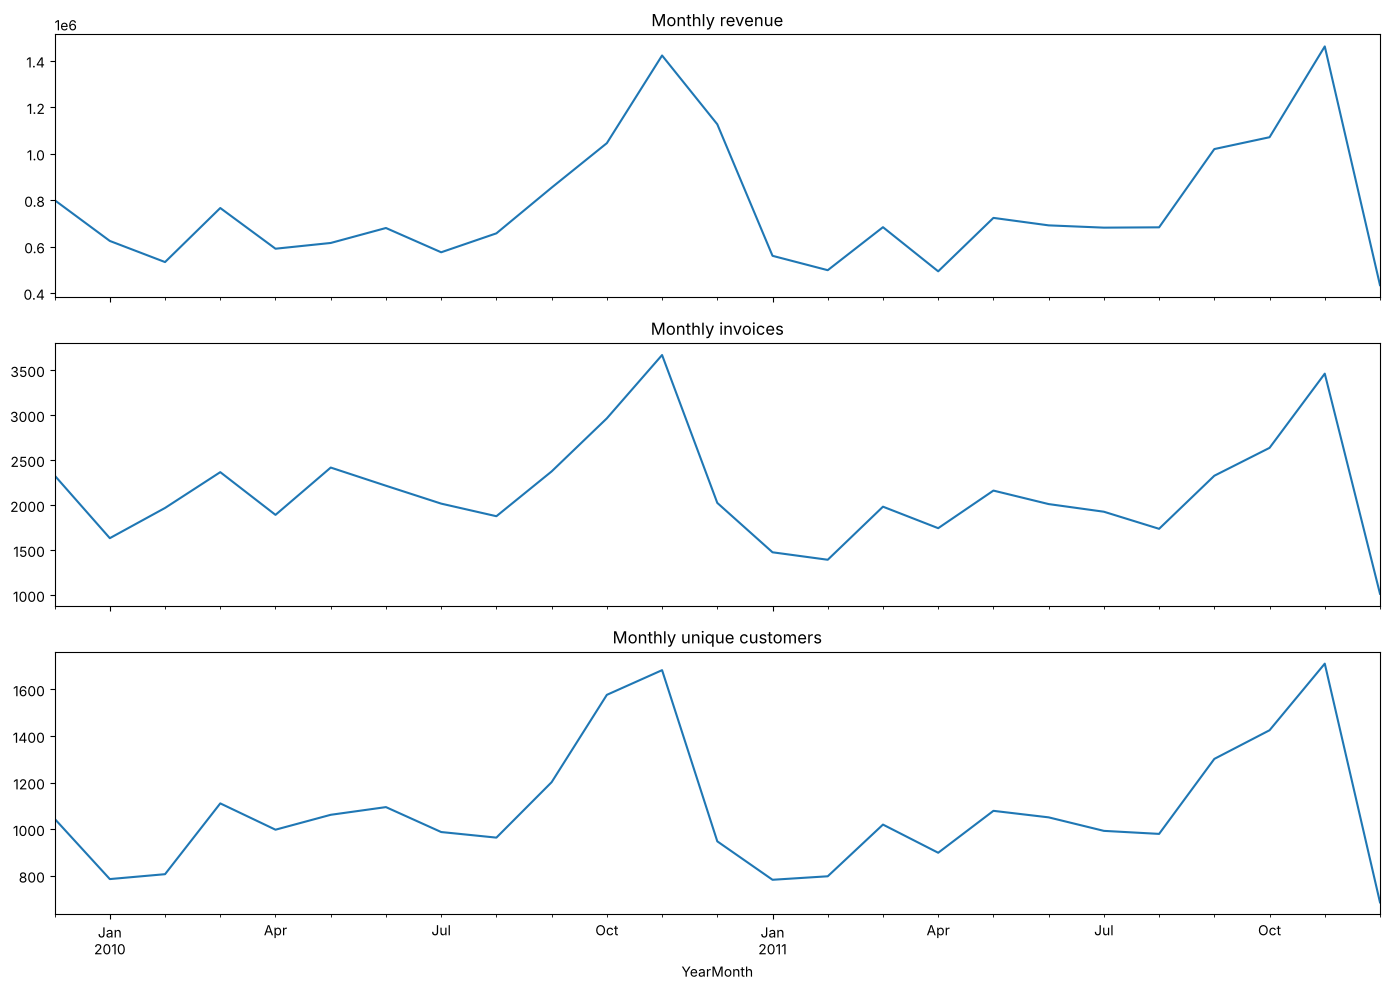

In [49]:
data['TotalPrice'] = data['Quantity'] * data['UnitPrice']

monthly_trend = data.groupby('YearMonth').agg(
    total_revenue=('TotalPrice', 'sum'),
    num_invoices=('InvoiceNo', 'nunique'),
    num_customers=('CustomerID', 'nunique')
)
display(monthly_trend)

# Plot the trends
fig, ax = plt.subplots(3, 1, figsize=(14, 10), sharex=True)
monthly_trend['total_revenue'].plot(ax=ax[0], title='Monthly revenue')
monthly_trend['num_invoices'].plot(ax=ax[1], title='Monthly invoices')
monthly_trend['num_customers'].plot(ax=ax[2], title='Monthly unique customers')
plt.tight_layout()
plt.show()

In [50]:
# Average revenue per invoice by month
monthly_trend['avg_revenue_per_invoice'] = monthly_trend['total_revenue'] / monthly_trend['num_invoices']
display(monthly_trend)

,total_revenue,num_invoices,num_customers,avg_revenue_per_invoice
YearMonth,,,,
2009-12,799847.110,2330,1045,343.282021
2010-01,624032.892,1633,786,382.138942
2010-02,533091.426,1969,807,270.742217
2010-03,765848.761,2367,1111,323.552497
2010-04,590580.432,1892,998,312.146106
2010-05,615322.830,2418,1062,254.475943
2010-06,679786.610,2216,1095,306.762911
2010-07,575236.360,2017,988,285.194031
2010-08,656776.340,1877,964,349.907480


In [51]:
dec_2011 = data[data['YearMonth'] == '2011-12']
print("Earliest date:", dec_2011['InvoiceDate'].min())
print("Latest date:", dec_2011['InvoiceDate'].max())
print("Days with data:", dec_2011['InvoiceDate'].dt.date.nunique())

Earliest date: 2011-12-01 08:12:00
Latest date: 2011-12-09 12:50:00
Days with data: 8


### Special StockCodes / descriptions

In [52]:
# Adjust bad debt
adjust_bd = data[data['Description'].astype(str).str.contains('Adjust bad debt', case=False, na=False)]
print("Adjust bad debt:", adjust_bd.shape[0])
display(adjust_bd)

# Amazon fee
amazon_fee = data[data['Description'].astype(str).str.contains('AMAZON FEE', case=False, na=False)]
print("Amazon fee:", amazon_fee.shape[0])
display(amazon_fee)

# Are all Amazon fee rows cancellations (InvoiceNo starting with C)?
print("% of Amazon fee rows that are cancellations:", amazon_fee['InvoiceNo'].astype(str).str.startswith('C').mean() * 100)
print(amazon_fee['StockCode'].value_counts())

Adjust bad debt: 6


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price,TotalPrice
179403,A506401,B,Adjust bad debt,1,2010-04-29 13:36:00,-53594.36,NaN,United Kingdom,2010-04,True,-433.813902,-53594.36
276274,A516228,B,Adjust bad debt,1,2010-07-19 11:24:00,-44031.79,NaN,United Kingdom,2010-07,True,-356.417401,-44031.79
403472,A528059,B,Adjust bad debt,1,2010-10-20 12:04:00,-38925.87,NaN,United Kingdom,2010-10,True,-315.091654,-38925.87
825443,A563185,B,Adjust bad debt,1,2011-08-12 14:50:00,11062.06,NaN,United Kingdom,2011-08,True,89.495282,11062.06
825444,A563186,B,Adjust bad debt,1,2011-08-12 14:51:00,-11062.06,NaN,United Kingdom,2011-08,True,-89.570543,-11062.06
825445,A563187,B,Adjust bad debt,1,2011-08-12 14:52:00,-11062.06,NaN,United Kingdom,2011-08,True,-89.570543,-11062.06


Amazon fee: 43


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price,TotalPrice
440688,C531400,AMAZONFEE,AMAZON FEE,-1,2010-11-08 10:08:00,6706.71,NaN,United Kingdom,2010-11,True,54.244418,-6706.71
440698,531411,AMAZONFEE,AMAZON FEE,1,2010-11-08 10:11:00,6706.71,NaN,United Kingdom,2010-11,False,54.244418,6706.71
517452,C537600,AMAZONFEE,AMAZON FEE,-1,2010-12-07 12:41:00,1.00,NaN,United Kingdom,2010-12,True,-0.029537,-1.00
517953,C537630,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:04:00,13541.33,NaN,United Kingdom,2010-12,True,109.561731,-13541.33
517955,537632,AMAZONFEE,AMAZON FEE,1,2010-12-07 15:08:00,13541.33,NaN,United Kingdom,2010-12,False,109.561731,13541.33
519170,C537644,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:34:00,13474.79,NaN,United Kingdom,2010-12,True,109.023176,-13474.79
519251,C537647,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:41:00,5519.25,NaN,United Kingdom,2010-12,True,44.633482,-5519.25
519294,C537651,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:49:00,13541.33,NaN,United Kingdom,2010-12,True,109.561731,-13541.33
519295,C537652,AMAZONFEE,AMAZON FEE,-1,2010-12-07 15:51:00,6706.71,NaN,United Kingdom,2010-12,True,54.244418,-6706.71
539975,C537600,AMAZONFEE,AMAZON FEE,-1,2010-12-07 12:41:00,1.00,NaN,United Kingdom,2010-12,True,-0.029537,-1.00


% of Amazon fee rows that are cancellations: 90.69767441860465
StockCode
AMAZONFEE    43
Name: count, dtype: int64


In [53]:
manual = data[data['StockCode'].astype(str).str.upper() == 'M']
print("Rows with StockCode = M:", manual.shape[0])
display(manual.sort_values('UnitPrice', ascending=False).head(20))
print(manual['UnitPrice'].describe())

Rows with StockCode = M: 1426


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price,TotalPrice
748142,C556445,M,Manual,-1,2011-06-10 15:31:00,38970.00,15098.0,United Kingdom,2011-06,True,315.373567,-38970.00
241827,512771,M,Manual,1,2010-06-17 16:53:00,25111.09,NaN,United Kingdom,2010-06,False,203.203811,25111.09
241824,C512770,M,Manual,-1,2010-06-17 16:52:00,25111.09,17399.0,United Kingdom,2010-06,True,203.203811,-25111.09
135015,502265,M,Manual,1,2010-03-23 15:28:00,10953.50,NaN,United Kingdom,2010-03,False,88.616630,10953.50
135013,502263,M,Manual,1,2010-03-23 15:22:00,10953.50,12918.0,United Kingdom,2010-03,False,88.616630,10953.50
135012,C502262,M,Manual,-1,2010-03-23 15:20:00,10953.50,12918.0,United Kingdom,2010-03,True,88.616630,-10953.50
135014,C502264,M,Manual,-1,2010-03-23 15:24:00,10953.50,12918.0,United Kingdom,2010-03,True,88.616630,-10953.50
342135,C522793,M,Manual,-1,2010-09-16 14:53:00,10468.80,14063.0,United Kingdom,2010-09,True,84.693618,-10468.80
372834,525399,M,Manual,1,2010-10-05 11:49:00,10468.80,NaN,United Kingdom,2010-10,False,84.693618,10468.80
372833,C525398,M,Manual,-1,2010-10-05 11:47:00,10468.80,14063.0,United Kingdom,2010-10,True,84.693618,-10468.80


count     1426.000000
mean       526.932784
std       1878.091072
min          0.000000
25%          1.250000
50%         11.325000
75%        337.942500
max      38970.000000
Name: UnitPrice, dtype: float64


In [54]:
bank_charges = data[data['Description'].astype(str).str.contains('BANK CHARGES', case=False, na=False)]
print(bank_charges.shape[0])
display(bank_charges)
print(bank_charges['StockCode'].value_counts())

102


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price,TotalPrice
18410,C490943,BANK CHARGES,Bank Charges,-1,2009-12-08 14:08:00,15.00,16703.0,United Kingdom,2009-12,True,0.083775,-15.00
18466,490948,BANK CHARGES,Bank Charges,1,2009-12-08 14:29:00,15.00,16805.0,United Kingdom,2009-12,False,0.083775,15.00
33435,C492206,BANK CHARGES,Bank Charges,-1,2009-12-15 16:32:00,848.43,NaN,United Kingdom,2009-12,True,6.829301,-848.43
55948,C494438,BANK CHARGES,Bank Charges,-1,2010-01-14 12:15:00,767.99,NaN,United Kingdom,2010-01,True,6.178244,-767.99
94431,498269,BANK CHARGES,Bank Charges,1,2010-02-17 15:03:00,15.00,16928.0,United Kingdom,2010-02,False,0.083775,15.00
...,...,...,...,...,...,...,...,...,...,...,...,...
966206,574546,BANK CHARGES,Bank Charges,1,2011-11-04 14:59:00,15.00,13651.0,United Kingdom,2011-11,False,0.083775,15.00
1006613,C577342,BANK CHARGES,Bank Charges,-1,2011-11-18 15:11:00,490.06,NaN,United Kingdom,2011-11,True,3.928764,-490.06
1006614,C577343,BANK CHARGES,Bank Charges,-1,2011-11-18 15:13:00,27.21,NaN,United Kingdom,2011-11,True,0.182599,-27.21
1031818,579137,BANK CHARGES,Bank Charges,1,2011-11-28 12:51:00,15.00,14704.0,United Kingdom,2011-11,False,0.083775,15.00


StockCode
BANK CHARGES    102
Name: count, dtype: int64


In [55]:
sc_22759 = data[data['StockCode'] == '22759']
print(sc_22759.shape[0])
display(sc_22759)
print("Missing Description:", sc_22759['Description'].isnull().sum())
print("Missing CustomerID:", sc_22759['CustomerID'].isnull().sum())

861


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price,TotalPrice
296420,518241,22759,NaN,9600,2010-08-05 15:55:00,0.00,NaN,United Kingdom,2010-08,False,-0.037631,0.00
297869,518397,22759,SET OF 3 NOTEBOOKS IN PARCEL,4,2010-08-08 12:43:00,1.65,16444.0,United Kingdom,2010-08,False,-0.024276,6.60
297888,518398,22759,SET OF 3 NOTEBOOKS IN PARCEL,1,2010-08-08 12:50:00,1.65,15046.0,United Kingdom,2010-08,False,-0.024276,1.65
298025,518404,22759,SET OF 3 NOTEBOOKS IN PARCEL,3,2010-08-08 13:55:00,1.65,16115.0,United Kingdom,2010-08,False,-0.024276,4.95
298227,518411,22759,SET OF 3 NOTEBOOKS IN PARCEL,1,2010-08-08 14:51:00,1.65,14575.0,United Kingdom,2010-08,False,-0.024276,1.65
...,...,...,...,...,...,...,...,...,...,...,...,...
1028909,578926,22759,SET OF 3 NOTEBOOKS IN PARCEL,1,2011-11-27 12:24:00,1.65,18156.0,United Kingdom,2011-11,False,-0.024276,1.65
1032438,579163,22759,SET OF 3 NOTEBOOKS IN PARCEL,144,2011-11-28 13:59:00,1.45,15838.0,United Kingdom,2011-11,False,-0.025895,208.80
1034435,579286,22759,SET OF 3 NOTEBOOKS IN PARCEL,1,2011-11-29 10:57:00,1.65,17772.0,United Kingdom,2011-11,False,-0.024276,1.65
1038978,579555,22759,SET OF 3 NOTEBOOKS IN PARCEL,2,2011-11-30 11:08:00,1.65,16241.0,United Kingdom,2011-11,False,-0.024276,3.30


Missing Description: 2
Missing CustomerID: 177


In [56]:
zero_price = data[data['UnitPrice'] == 0]
print("Rows with UnitPrice = 0:", zero_price.shape[0])
display(zero_price.head(20))
print("Missing Description in this group:", zero_price['Description'].isnull().sum())
print(zero_price['Description'].value_counts().head(20))

Rows with UnitPrice = 0: 6202


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price,TotalPrice
263,489464,21733,85123a mixed,-96,2009-12-01 10:52:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631,-0.0
283,489463,71477,short,-240,2009-12-01 10:52:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631,-0.0
284,489467,85123A,21733 mixed,-192,2009-12-01 10:53:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631,-0.0
470,489521,21646,NaN,-50,2009-12-01 11:44:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631,-0.0
3114,489655,20683,NaN,-44,2009-12-01 17:26:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631,-0.0
3161,489659,21350,NaN,230,2009-12-01 17:39:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631,0.0
3162,489660,35956,lost,-1043,2009-12-01 17:43:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631,-0.0
3168,489663,35605A,damages,-117,2009-12-01 18:02:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631,-0.0
3731,489781,84292,NaN,17,2009-12-02 11:45:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631,0.0
4296,489806,18010,NaN,-770,2009-12-02 12:42:00,0.0,NaN,United Kingdom,2009-12,False,-0.037631,-0.0


Missing Description in this group: 4382
Description
check                                  162
?                                       92
damages                                 84
damaged                                 81
found                                   28
missing                                 27
sold as set on dotcom                   20
Damaged                                 17
adjustment                              16
OWL DOORSTOP                            15
POLYESTER FILLER PAD 45x45cm            12
dotcom                                  12
amazon                                  11
POLYESTER FILLER PAD 40x40cm            10
IVORY KITCHEN SCALES                    10
FRENCH BLUE METAL DOOR SIGN 1           10
smashed                                  9
Found                                    9
PICNIC BASKET WICKER LARGE               9
AIRLINE BAG VINTAGE WORLD CHAMPION       9
Name: count, dtype: int64


In [57]:
perfect_dup = data[data.duplicated(keep=False)]
print("Rows in exact-duplicate groups:", perfect_dup.shape[0])
display(perfect_dup.sort_values(['InvoiceNo','StockCode']).head(20))

# Rows that would be removed by drop_duplicates (keeping one copy)
print("Rows removed by drop_duplicates:", data.duplicated(keep='first').sum())

Rows in exact-duplicate groups: 67242


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price,TotalPrice
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,2009-12,False,-0.021848,1.95
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,2009-12,False,-0.021848,1.95
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,2009-12,False,-0.030751,5.10


Rows removed by drop_duplicates: 34335


## 6. Cleaning

In [58]:
data_clean = data.copy()

# Remove bad-debt adjustments (StockCode = 'B', InvoiceNo starting with 'A')
data_clean = data_clean[data_clean['StockCode'] != 'B']

# Remove Amazon fees
data_clean = data_clean[data_clean['StockCode'] != 'AMAZONFEE']

print("Rows after removing bad-debt adjustments + Amazon fees:", data_clean.shape[0])

Rows after removing bad-debt adjustments + Amazon fees: 1067322


In [59]:
before = data_clean.shape[0]

data_clean = data_clean[~((data_clean['Description'].isna()) & (data_clean['UnitPrice'] == 0))]

print("Rows removed:", before - data_clean.shape[0])
print("Rows remaining:", data_clean.shape[0])

Rows removed: 4382
Rows remaining: 1062940


In [60]:
# Descriptions containing lowercase letters (not all caps)
lowercase_desc = data_clean[data_clean['Description'].notna() & 
                              data_clean['Description'].astype(str).str.contains(r'[a-z]', regex=True)]

print("Rows with lowercase characters in Description:", lowercase_desc.shape[0])
print(lowercase_desc['Description'].value_counts().head(50))

Rows with lowercase characters in Description: 5961
Description
Manual                                 1426
BAG 250g SWIRLY MARBLES                 598
BAG 125g SWIRLY MARBLES                 596
POLYESTER FILLER PAD 40x40cm            398
POLYESTER FILLER PAD 45x45cm            372
3 TRADITIONAl BISCUIT CUTTERS  SET      268
BAG 500g SWIRLY MARBLES                 240
FRENCH BLUE METAL DOOR SIGN No          186
Discount                                177
check                                   162
Bank Charges                             96
damages                                  84
damaged                                  81
ESSENTIAL BALM 3.5g TIN IN ENVELOPE      80
Next Day Carriage                        80
POLYESTER FILLER PAD 45x30cm             65
POLYESTER FILLER PAD 65CMx65CM           52
POLYESTER FILLER PAD 30CMx30CM           52
FRENCH BLUE METAL DOOR SIGN, No          48
NUMBER TILE COTTAGE GARDEN No            42
NUMBER TILE VINTAGE FONT No              39
Adjustment b

**What is StockCode `M` (Manual)?**

"Manual" means a staff member keyed in a line item that is not in the standard product catalog, so it has no fixed product code and no fixed list price. It is typically used for:
- Special one-off charges (extra shipping, handling fees for problem orders)
- Adjustments or credits for a customer
- "Exception" transactions that don't correspond to any product

**Why does UnitPrice vary so much for Manual rows?**
Each Manual entry is a different situation. The UnitPrice is the amount of that specific transaction, not the price of a product (it could be £5 or £500 depending on the adjustment). So Manual UnitPrices don't follow a normal product price distribution, shouldn't be treated as product prices, and should be excluded from product-level price/revenue analysis.

In [61]:
manual_rows = data_clean[data_clean['StockCode'] == 'M']
print(manual_rows[['InvoiceNo','Description','UnitPrice','Quantity','CustomerID']])
print(manual_rows['UnitPrice'].describe())

        InvoiceNo Description  UnitPrice  Quantity  CustomerID
2697       489609      Manual       4.00         1         NaN
3053      C489651      Manual       5.10        -1     17804.0
5897      C489859      Manual      69.57        -1         NaN
9259      C490126      Manual       5.95        -1     15884.0
9307      C490129      Manual    1998.49        -1     15482.0
...           ...         ...        ...       ...         ...
1056893    580956      Manual       1.25         4     17841.0
1058543   C581009      Manual     125.00        -1     16971.0
1059769   C581145      Manual       9.95        -1     17490.0
1063782    581405      Manual       0.42         3     13521.0
1067002   C581499      Manual     224.69        -1     15498.0

[1421 rows x 5 columns]
count     1421.000000
mean       528.776284
std       1881.136877
min          0.000000
25%          1.250000
50%         12.680000
75%        339.020000
max      38970.000000
Name: UnitPrice, dtype: float64


In [62]:
sc_22759 = data_clean[data_clean['StockCode'] == '22759']
print("Total rows:", sc_22759.shape[0])
display(sc_22759)

print("Missing Description:", sc_22759['Description'].isnull().sum())
print("Missing CustomerID:", sc_22759['CustomerID'].isnull().sum())
print("UnitPrice describe:\n", sc_22759['UnitPrice'].describe())

Total rows: 859


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price,TotalPrice
297869,518397,22759,SET OF 3 NOTEBOOKS IN PARCEL,4,2010-08-08 12:43:00,1.65,16444.0,United Kingdom,2010-08,False,-0.024276,6.60
297888,518398,22759,SET OF 3 NOTEBOOKS IN PARCEL,1,2010-08-08 12:50:00,1.65,15046.0,United Kingdom,2010-08,False,-0.024276,1.65
298025,518404,22759,SET OF 3 NOTEBOOKS IN PARCEL,3,2010-08-08 13:55:00,1.65,16115.0,United Kingdom,2010-08,False,-0.024276,4.95
298227,518411,22759,SET OF 3 NOTEBOOKS IN PARCEL,1,2010-08-08 14:51:00,1.65,14575.0,United Kingdom,2010-08,False,-0.024276,1.65
298760,518481,22759,SET OF 3 NOTEBOOKS IN PARCEL,4,2010-08-09 12:22:00,1.65,17841.0,United Kingdom,2010-08,False,-0.024276,6.60
...,...,...,...,...,...,...,...,...,...,...,...,...
1028909,578926,22759,SET OF 3 NOTEBOOKS IN PARCEL,1,2011-11-27 12:24:00,1.65,18156.0,United Kingdom,2011-11,False,-0.024276,1.65
1032438,579163,22759,SET OF 3 NOTEBOOKS IN PARCEL,144,2011-11-28 13:59:00,1.45,15838.0,United Kingdom,2011-11,False,-0.025895,208.80
1034435,579286,22759,SET OF 3 NOTEBOOKS IN PARCEL,1,2011-11-29 10:57:00,1.65,17772.0,United Kingdom,2011-11,False,-0.024276,1.65
1038978,579555,22759,SET OF 3 NOTEBOOKS IN PARCEL,2,2011-11-30 11:08:00,1.65,16241.0,United Kingdom,2011-11,False,-0.024276,3.30


Missing Description: 0
Missing CustomerID: 175
UnitPrice describe:
 count    859.000000
mean       1.969523
std        0.685880
min        0.000000
25%        1.650000
50%        1.650000
75%        1.650000
max        3.950000
Name: UnitPrice, dtype: float64


In [63]:
# Perfect duplicates: all columns identical
perfect_dup = data_clean[data_clean.duplicated(keep=False)]
print("Rows in exact-duplicate groups:", perfect_dup.shape[0])
print("Rows removed by drop_duplicates (keeping one copy):", data_clean.duplicated(keep='first').sum())

display(perfect_dup.sort_values(['InvoiceNo','StockCode','InvoiceDate']).head(20))

Rows in exact-duplicate groups: 67014


Rows removed by drop_duplicates (keeping one copy): 34221


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,YearMonth,InvoiceNo_HasLetter,zscore_price,TotalPrice
379,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,2009-12,False,-0.021848,1.95
391,489517,21491,SET OF THREE VINTAGE GIFT WRAPS,1,2009-12-01 11:34:00,1.95,16329.0,United Kingdom,2009-12,False,-0.021848,1.95
365,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
386,489517,21821,GLITTER STAR GARLAND WITH BELLS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
363,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
371,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
394,489517,21912,VINTAGE SNAKES & LADDERS,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
362,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
385,489517,21913,VINTAGE SEASIDE JIGSAW PUZZLES,1,2009-12-01 11:34:00,3.75,16329.0,United Kingdom,2009-12,False,-0.007279,3.75
368,489517,22130,PARTY CONE CHRISTMAS DECORATION,6,2009-12-01 11:34:00,0.85,16329.0,United Kingdom,2009-12,False,-0.030751,5.10


In [64]:
keep_lowercase = [  
    "BAG 250g SWIRLY MARBLES",
    "BAG 125g SWIRLY MARBLES",
    "BAG 500g SWIRLY MARBLES",
    "POLYESTER FILLER PAD 40x40cm",
    "POLYESTER FILLER PAD 45x45cm",
    "POLYESTER FILLER PAD 45x30cm",
    "POLYESTER FILLER PAD 65CMx65CM",
    "POLYESTER FILLER PAD 30CMx30CM",
    "3 TRADITIONAl BISCUIT CUTTERS  SET",
    "ESSENTIAL BALM 3.5g TIN IN ENVELOPE",
    "FRENCH BLUE METAL DOOR SIGN No",
    "FRENCH BLUE METAL DOOR SIGN, No",
    "NUMBER TILE COTTAGE GARDEN No",
    "NUMBER TILE VINTAGE FONT No",
    "FOLK ART GREETING CARD,pack/12",
    "THE KING GIFT BAG 25x24x12cm",
    "Dad's Cab Electronic Meter",
    "Hypochondriac Pill Stress Ball"
]

In [65]:
data_clean["Description"] = data_clean["Description"].str.upper()

In [66]:
remove_desc = [
    "Discount",
    "Manual",
    "check",
    "checked",
    "damages",
    "damaged",
    "Damaged",
    "damages?",
    "Adjustment by john on 26/01/2010 16",
    "Adjustment by john on 26/01/2010 17",
    "adjustment",
    "found",
    "Found",
    "missing",
    "sold as set on dotcom",
    "dotcom",
    "amazon",
    "Amazon",
    "Bank Charges",
    " Bank Charges",
    "Next Day Carriage",
    "CRUK Commission",
    "Dotcomgiftshop Gift Voucher £10.00",
    "Dotcomgiftshop Gift Voucher £20.00",
    "Dotcomgiftshop Gift Voucher £30.00",
    "This is a test product.",
    "thrown away",
    "given away",
    "crushed",
    "smashed",
    "Unsaleable, destroyed.",
    "mailout"
]

In [67]:
# Descriptions were upper-cased above, so compare in upper case too
before = data_clean.shape[0]
data_clean = data_clean[
    ~data_clean["Description"].str.strip().isin([d.strip().upper() for d in remove_desc])
]
print("Rows removed (non-product descriptions):", before - data_clean.shape[0])

Rows removed (non-product descriptions): 2506


In [68]:
print("Perfect duplicates:",
      data_clean.duplicated().sum())

data_clean = data_clean.drop_duplicates()

Perfect duplicates: 34175


## 7. Output tables

In [69]:
product_table = data_clean[[
    "InvoiceNo",
    "InvoiceDate",
    "CustomerID",
    "StockCode",
    "Description",
    "Quantity",
    "UnitPrice",
    "TotalPrice",
    "Country"
]].copy()

print("Shape:", product_table.shape)
display(product_table.head(20)) # transaction-level table

Shape: (1026259, 9)


,InvoiceNo,InvoiceDate,CustomerID,StockCode,Description,Quantity,UnitPrice,TotalPrice,Country
0,489434,2009-12-01 07:45:00,13085.0,85048,15CM CHRISTMAS GLASS BALL 20 LIGHTS,12,6.95,83.40,United Kingdom
1,489434,2009-12-01 07:45:00,13085.0,79323P,PINK CHERRY LIGHTS,12,6.75,81.00,United Kingdom
2,489434,2009-12-01 07:45:00,13085.0,79323W,WHITE CHERRY LIGHTS,12,6.75,81.00,United Kingdom
3,489434,2009-12-01 07:45:00,13085.0,22041,"RECORD FRAME 7"" SINGLE SIZE",48,2.10,100.80,United Kingdom
4,489434,2009-12-01 07:45:00,13085.0,21232,STRAWBERRY CERAMIC TRINKET BOX,24,1.25,30.00,United Kingdom
5,489434,2009-12-01 07:45:00,13085.0,22064,PINK DOUGHNUT TRINKET POT,24,1.65,39.60,United Kingdom
6,489434,2009-12-01 07:45:00,13085.0,21871,SAVE THE PLANET MUG,24,1.25,30.00,United Kingdom
7,489434,2009-12-01 07:45:00,13085.0,21523,FANCY FONT HOME SWEET HOME DOORMAT,10,5.95,59.50,United Kingdom
8,489435,2009-12-01 07:46:00,13085.0,22350,CAT BOWL,12,2.55,30.60,United Kingdom
9,489435,2009-12-01 07:46:00,13085.0,22349,"DOG BOWL , CHASING BALL DESIGN",12,3.75,45.00,United Kingdom


In [70]:
customer_table = (
    data_clean
    .groupby("CustomerID", as_index=False)
    .agg({
        "Quantity": "sum",
        "UnitPrice":"sum",
        "TotalPrice": "sum"
    })
)

print("Shape:", customer_table.shape)
display(customer_table.head(20)) 

Shape: (5878, 4)


,CustomerID,Quantity,UnitPrice,TotalPrice
0,12346.0,24,171.44,169.36
1,12347.0,2967,554.57,4921.53
2,12348.0,2714,193.10,2019.40
3,12349.0,1619,1504.59,4404.54
4,12350.0,197,65.30,334.40
5,12351.0,261,49.46,300.93
6,12352.0,658,585.10,1889.21
7,12353.0,212,63.08,406.76
8,12354.0,530,261.22,1079.40
9,12355.0,543,107.43,947.61


In [71]:
invoice_per_customer = (
    data_clean.groupby("CustomerID")["InvoiceNo"]
    .nunique()
)

print(invoice_per_customer.describe())

count    5878.000000
mean        7.505784
std        15.454045
min         1.000000
25%         2.000000
50%         4.000000
75%         8.000000
max       468.000000
Name: InvoiceNo, dtype: float64
